### **“Lung Cancer Prediction Using Gaussian Naive Bayes and K-Nearest Neighbors (KNN)”**

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("C:/Users/48swe/OneDrive/Documents/Downloads/survey lung cancer.csv")
print(df.head())

  GENDER  AGE  SMOKING  YELLOW_FINGERS  ANXIETY  PEER_PRESSURE  \
0      M   69        1               2        2              1   
1      M   74        2               1        1              1   
2      F   59        1               1        1              2   
3      M   63        2               2        2              1   
4      F   63        1               2        1              1   

   CHRONIC DISEASE  FATIGUE   ALLERGY   WHEEZING  ALCOHOL CONSUMING  COUGHING  \
0                1         2         1         2                  2         2   
1                2         2         2         1                  1         1   
2                1         2         1         2                  1         2   
3                1         1         1         1                  2         1   
4                1         1         1         2                  1         2   

   SHORTNESS OF BREATH  SWALLOWING DIFFICULTY  CHEST PAIN LUNG_CANCER  
0                    2                      

In [4]:
df.shape
df.dtypes


GENDER                   object
AGE                       int64
SMOKING                   int64
YELLOW_FINGERS            int64
ANXIETY                   int64
PEER_PRESSURE             int64
CHRONIC DISEASE           int64
FATIGUE                   int64
ALLERGY                   int64
WHEEZING                  int64
ALCOHOL CONSUMING         int64
COUGHING                  int64
SHORTNESS OF BREATH       int64
SWALLOWING DIFFICULTY     int64
CHEST PAIN                int64
LUNG_CANCER              object
dtype: object

In [10]:
df.isnull().sum()

GENDER                   0
AGE                      0
SMOKING                  0
YELLOW_FINGERS           0
ANXIETY                  0
PEER_PRESSURE            0
CHRONIC DISEASE          0
FATIGUE                  0
ALLERGY                  0
WHEEZING                 0
ALCOHOL CONSUMING        0
COUGHING                 0
SHORTNESS OF BREATH      0
SWALLOWING DIFFICULTY    0
CHEST PAIN               0
LUNG_CANCER              0
dtype: int64

In [5]:
#  Clean column names and check duplicates

df.columns = (
    df.columns
    .str.strip()
    .str.upper()
    .str.replace(r'\s+', '_', regex=True)
)

print("Column Names:")
print(df.columns.tolist())

print("\nDuplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Shape After Removing Duplicates:", df.shape)

Column Names:
['GENDER', 'AGE', 'SMOKING', 'YELLOW_FINGERS', 'ANXIETY', 'PEER_PRESSURE', 'CHRONIC_DISEASE', 'FATIGUE', 'ALLERGY', 'WHEEZING', 'ALCOHOL_CONSUMING', 'COUGHING', 'SHORTNESS_OF_BREATH', 'SWALLOWING_DIFFICULTY', 'CHEST_PAIN', 'LUNG_CANCER']

Duplicate Rows: 33
Shape After Removing Duplicates: (276, 16)


LUNG_CANCER
YES    238
NO      38
Name: count, dtype: int64


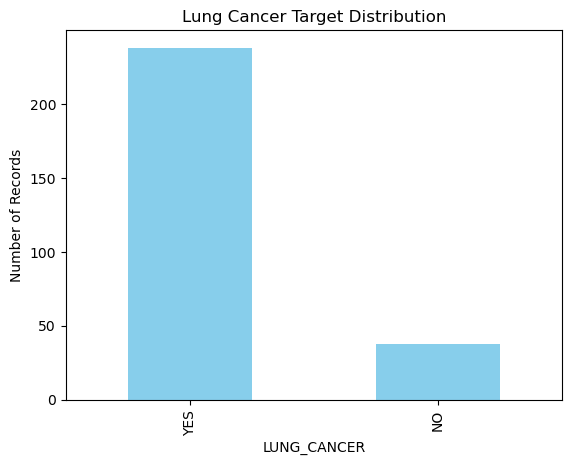

In [6]:
#  Check lung cancer class distribution

print(df['LUNG_CANCER'].value_counts())

df['LUNG_CANCER'].value_counts().plot(
    kind='bar',
    color='skyblue'
)

plt.title("Lung Cancer Target Distribution")
plt.xlabel("LUNG_CANCER")
plt.ylabel("Number of Records")
plt.show()

In [7]:
X = df.drop(columns=['LUNG_CANCER'])
y = df['LUNG_CANCER']

print("Independent Variables (X):")
print(X.head())

print("\nTarget Variable (y):")
print(y.head())

Independent Variables (X):
  GENDER  AGE  SMOKING  YELLOW_FINGERS  ANXIETY  PEER_PRESSURE  \
0      M   69        1               2        2              1   
1      M   74        2               1        1              1   
2      F   59        1               1        1              2   
3      M   63        2               2        2              1   
4      F   63        1               2        1              1   

   CHRONIC_DISEASE  FATIGUE  ALLERGY  WHEEZING  ALCOHOL_CONSUMING  COUGHING  \
0                1        2        1         2                  2         2   
1                2        2        2         1                  1         1   
2                1        2        1         2                  1         2   
3                1        1        1         1                  2         1   
4                1        1        1         2                  1         2   

   SHORTNESS_OF_BREATH  SWALLOWING_DIFFICULTY  CHEST_PAIN  
0                    2                   

In [8]:
X = pd.get_dummies(
    X,
    columns=['GENDER'],
    drop_first=True,
    dtype=int
)

y = y.astype(str).str.strip().str.upper().map({
    'NO': 0,
    'YES': 1
})

print("Encoded Features:")
print(X.head())

print("\nEncoded Target:")
print(y.value_counts())

Encoded Features:
   AGE  SMOKING  YELLOW_FINGERS  ANXIETY  PEER_PRESSURE  CHRONIC_DISEASE  \
0   69        1               2        2              1                1   
1   74        2               1        1              1                2   
2   59        1               1        1              2                1   
3   63        2               2        2              1                1   
4   63        1               2        1              1                1   

   FATIGUE  ALLERGY  WHEEZING  ALCOHOL_CONSUMING  COUGHING  \
0        2        1         2                  2         2   
1        2        2         1                  1         1   
2        2        1         2                  1         2   
3        1        1         1                  2         1   
4        1        1         2                  1         2   

   SHORTNESS_OF_BREATH  SWALLOWING_DIFFICULTY  CHEST_PAIN  GENDER_M  
0                    2                      2           2         1  
1           

In [9]:
X = X.apply(pd.to_numeric, errors='coerce')

X = X.fillna(X.median())

print("Missing Values in X:")
print(X.isnull().sum().sum())

print("\nMissing Values in y:")
print(y.isnull().sum())

Missing Values in X:
0

Missing Values in y:
0


In [10]:
valid_rows = y.notna()

X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

print("Final X Shape:", X.shape)
print("Final y Shape:", y.shape)

Final X Shape: (276, 15)
Final y Shape: (276,)


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (220, 15)
Testing Data: (56, 15)


In [14]:
# Build Gaussian Naive Bayes

from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()

nb_model.fit(X_train, y_train)



,priors,None
,var_smoothing,1e-09


In [13]:
#  Predict using Naive Bayes

y_pred_nb = nb_model.predict(X_test)

print("Predicted Values:")
print(y_pred_nb)

print("\nActual Values:")
print(y_test.to_numpy())

Predicted Values:
[1 1 1 1 1 1 1 1 1 1 0 1 1 0 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 0 1 1 1
 1 1 1 1 1 1 1 1 0 1 1 1 0 1 1 1 1 1 1]

Actual Values:
[1 1 1 1 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 1 1 0 0 1 1
 1 1 1 0 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1]


In [15]:
#  Calculate accuracy

from sklearn.metrics import accuracy_score

nb_accuracy = accuracy_score(y_test, y_pred_nb)

print("Naive Bayes Accuracy:", nb_accuracy)
print("Accuracy Percentage:", round(nb_accuracy * 100, 2), "%")

Naive Bayes Accuracy: 0.8928571428571429
Accuracy Percentage: 89.29 %


In [16]:
#  Classification report

from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_nb,
    labels=[0, 1],
    target_names=['NO', 'YES'],
    zero_division=0
))

              precision    recall  f1-score   support

          NO       0.67      0.50      0.57         8
         YES       0.92      0.96      0.94        48

    accuracy                           0.89        56
   macro avg       0.79      0.73      0.76        56
weighted avg       0.88      0.89      0.89        56



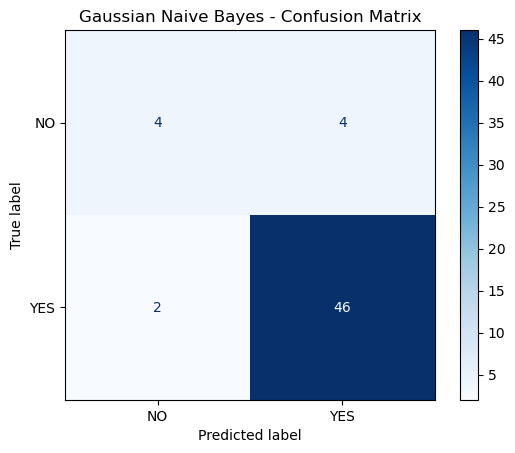

In [17]:
# Confusion matrix

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_nb,
    labels=[0, 1],
    display_labels=['NO', 'YES'],
    cmap='Blues'
)

plt.title("Gaussian Naive Bayes - Confusion Matrix")
plt.show()

In [18]:
#  Class priors and feature means

print("Classes:", nb_model.classes_)

print("\nClass Priors:")
print(nb_model.class_prior_)

feature_means = pd.DataFrame(
    nb_model.theta_,
    index=['NO', 'YES'],
    columns=X_train.columns
)

print("\nFeature Means:")
print(feature_means)

Classes: [0 1]

Class Priors:
[0.13636364 0.86363636]

Feature Means:
           AGE   SMOKING  YELLOW_FINGERS   ANXIETY  PEER_PRESSURE  \
NO   62.333333  1.466667        1.366667  1.300000       1.200000   
YES  63.552632  1.573684        1.636842  1.521053       1.526316   

     CHRONIC_DISEASE   FATIGUE   ALLERGY  WHEEZING  ALCOHOL_CONSUMING  \
NO          1.300000  1.500000  1.133333  1.266667           1.166667   
YES         1.563158  1.684211  1.600000  1.573684           1.594737   

     COUGHING  SHORTNESS_OF_BREATH  SWALLOWING_DIFFICULTY  CHEST_PAIN  \
NO   1.333333             1.600000               1.166667    1.300000   
YES  1.626316             1.668421               1.515789    1.610526   

     GENDER_M  
NO   0.400000  
YES  0.547368  


In [19]:
#  Scale the features

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled Training Data Shape:", X_train_scaled.shape)
print("Scaled Testing Data Shape:", X_test_scaled.shape)

Scaled Training Data Shape: (220, 15)
Scaled Testing Data Shape: (56, 15)


In [20]:
#  Build KNN with K = 5

from sklearn.neighbors import KNeighborsClassifier

knn5 = KNeighborsClassifier(n_neighbors=5)

knn5.fit(X_train_scaled, y_train)

y_pred_knn5 = knn5.predict(X_test_scaled)

print("KNN Model Trained Successfully")
print("\nPredicted Values:")
print(y_pred_knn5)

KNN Model Trained Successfully

Predicted Values:
[1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 0 1 1 1 0 1 1 1 1 1 1]


In [21]:
# Predict and evaluate KNN

from sklearn.metrics import accuracy_score, classification_report

knn5_accuracy = accuracy_score(y_test, y_pred_knn5)

print("KNN Accuracy:", knn5_accuracy)
print("Accuracy Percentage:", round(knn5_accuracy * 100, 2), "%")

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred_knn5,
    labels=[0, 1],
    target_names=['NO', 'YES'],
    zero_division=0
))

KNN Accuracy: 0.8928571428571429
Accuracy Percentage: 89.29 %

Classification Report:

              precision    recall  f1-score   support

          NO       0.75      0.38      0.50         8
         YES       0.90      0.98      0.94        48

    accuracy                           0.89        56
   macro avg       0.83      0.68      0.72        56
weighted avg       0.88      0.89      0.88        56



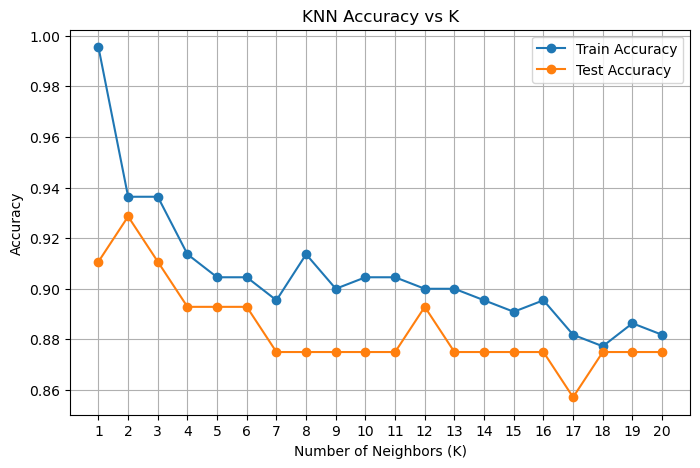

Best K: 2


In [22]:
#  Find the Best K

k_values = range(1, 21)

train_acc = []
test_acc = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)

    knn.fit(X_train_scaled, y_train)

    train_acc.append(knn.score(X_train_scaled, y_train))
    test_acc.append(knn.score(X_test_scaled, y_test))

plt.figure(figsize=(8, 5))

plt.plot(k_values, train_acc, marker='o', label='Train Accuracy')
plt.plot(k_values, test_acc, marker='o', label='Test Accuracy')

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy vs K")
plt.xticks(list(k_values))
plt.legend()
plt.grid(True)
plt.show()

best_k = list(k_values)[int(np.argmax(test_acc))]

print("Best K:", best_k)

# For a more reliable choice of K,
# use cross-validation on training data.

In [23]:
#  Pick K with Cross-Validation

from sklearn.model_selection import cross_val_score

cv_scores = []

for k in range(1, 21):
    knn = KNeighborsClassifier(n_neighbors=k)

    scores = cross_val_score(
        knn,
        X_train_scaled,
        y_train,
        cv=5,
        scoring='accuracy'
    )

    cv_scores.append(scores.mean())

best_k_cv = list(range(1, 21))[int(np.argmax(cv_scores))]

print("Best K using 5-fold cross-validation:", best_k_cv)
print("Best Mean CV Accuracy:", max(cv_scores))

Best K using 5-fold cross-validation: 6
Best Mean CV Accuracy: 0.8909090909090909


In [24]:
#  Build the Final KNN Model

knn = KNeighborsClassifier(
    n_neighbors=best_k_cv,
    metric='minkowski',
    p=2
)  # p=2 means Euclidean distance

knn.fit(X_train_scaled, y_train)

print("Final KNN Model Trained Successfully")

Final KNN Model Trained Successfully


In [25]:
# Predict and Evaluate

from sklearn.metrics import confusion_matrix

y_pred_knn = knn.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_knn))

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred_knn,
    labels=[0, 1],
    target_names=['NO', 'YES'],
    zero_division=0
))

print("Confusion Matrix:\n")

print(confusion_matrix(y_test, y_pred_knn, labels=[0, 1]))

Accuracy: 0.8928571428571429

Classification Report:

              precision    recall  f1-score   support

          NO       0.75      0.38      0.50         8
         YES       0.90      0.98      0.94        48

    accuracy                           0.89        56
   macro avg       0.83      0.68      0.72        56
weighted avg       0.88      0.89      0.88        56

Confusion Matrix:

[[ 3  5]
 [ 1 47]]


In [26]:
# See the Neighbors of One Record

sample = X_test.iloc[[0]]
sample_scaled = scaler.transform(sample)

distances, indices = knn.kneighbors(sample_scaled)

print("Actual Class:", y_test.iloc[0])
print("Predicted Class:", knn.predict(sample_scaled)[0])

print("\nNearest Neighbors:")

for d, i in zip(distances[0], indices[0]):
    print(
        f"Distance = {d:.3f} -> "
        f"Class = {y_train.iloc[i]}"
    )

Actual Class: 1
Predicted Class: 1

Nearest Neighbors:
Distance = 2.639 -> Class = 1
Distance = 4.029 -> Class = 1
Distance = 4.033 -> Class = 1
Distance = 4.055 -> Class = 1
Distance = 4.057 -> Class = 1
Distance = 4.134 -> Class = 1


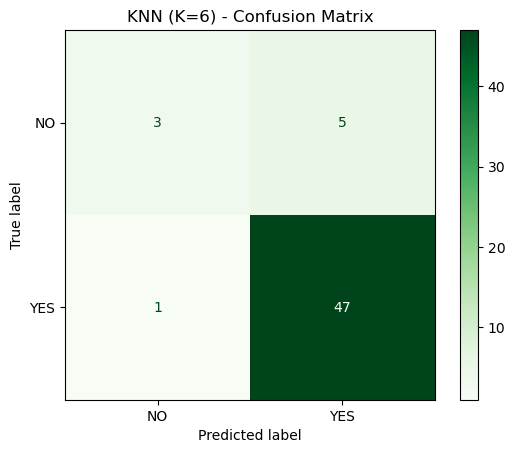

In [27]:
# Confusion Matrix Chart

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_knn,
    labels=[0, 1],
    display_labels=['NO', 'YES'],
    cmap='Greens'
)

plt.title(f"KNN (K={best_k_cv}) - Confusion Matrix")
plt.show()

In [28]:
#  Compare KNN With and Without Scaling

knn_unscaled = KNeighborsClassifier(n_neighbors=best_k_cv)

knn_unscaled.fit(X_train, y_train)

print(
    "KNN Accuracy WITHOUT Scaling:",
    knn_unscaled.score(X_test, y_test)
)

print(
    "KNN Accuracy WITH Scaling:",
    knn.score(X_test_scaled, y_test)
)

KNN Accuracy WITHOUT Scaling: 0.9107142857142857
KNN Accuracy WITH Scaling: 0.8928571428571429


In [29]:
#  Compare Both Models

results = pd.DataFrame({
    "Model": [
        "Gaussian Naive Bayes",
        f"KNN (K={best_k_cv})"
    ],
    "Test Accuracy": [
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_knn)
    ]
})

print(results)

                  Model  Test Accuracy
0  Gaussian Naive Bayes       0.892857
1             KNN (K=6)       0.892857


In [30]:
#  Compare YES Class Recall

from sklearn.metrics import recall_score

nb_recall = recall_score(
    y_test, y_pred_nb, pos_label=1
)

knn_recall = recall_score(
    y_test, y_pred_knn, pos_label=1
)

print("Naive Bayes YES Recall:", nb_recall)
print("KNN YES Recall:", knn_recall)

if nb_recall > knn_recall:
    print("Naive Bayes has higher YES class recall.")
elif knn_recall > nb_recall:
    print("KNN has higher YES class recall.")
else:
    print("Both models have equal YES class recall.")

Naive Bayes YES Recall: 0.9583333333333334
KNN YES Recall: 0.9791666666666666
KNN has higher YES class recall.


Gaussian Naive Bayes assumes that the input features are conditionally independent given the target class.
1. Features such as smoking, coughing, wheezing, and shortness of breath may be associated with one another in this survey dataset.
2. The independence assumption simplifies the probability calculations.
3. Correlations between features may affect the probability estimates.
4. Despite this limitation, Naive Bayes can still perform well in practice.
5. Its performance should be assessed using accuracy, recall, precision, and the confusion matrix.
Conclusion: Naive Bayes is computationally efficient, but its independence assumption may not fully represent relationships between the survey features.

K-Nearest Neighbors is generally slower at prediction time than Gaussian Naive Bayes when the training dataset contains 5 million rows.

KNN:
- Stores the training observations.
- Calculates distances between new observations and training observations.
- Searches for the nearest neighbors before making a prediction.
- Can become computationally expensive with very large datasets.
Gaussian Naive Bayes:
- Learns class priors and feature-distribution parameters during training.
- Uses the learned parameters to predict new observations.
- Usually requires less computation at prediction time.
Conclusion: Gaussian Naive Bayes is generally faster for prediction on very large datasets, while KNN can require substantially more computation because of its distance calculations.

### Final project conclusion
The project compares Gaussian Naive Bayes and K-Nearest Neighbors for classifying the LUNG_CANCER target using survey features. Both models are evaluated using accuracy, precision, recall, F1-score, and confusion matrices. The best-performing model should be selected based on the actual test results and the evaluation metric most relevant to the task.